# Vision Adapter 학습

Vision Encoder와 LLM 본체는 그대로 두고, 둘을 잇는 **Projector(어댑터)** 모듈만 학습합니다. Qwen3-VL에서는 `visual.merger`(및 DeepStack용 `visual.deepstack_merger_list`)가 이 역할을 하는 모듈입니다.



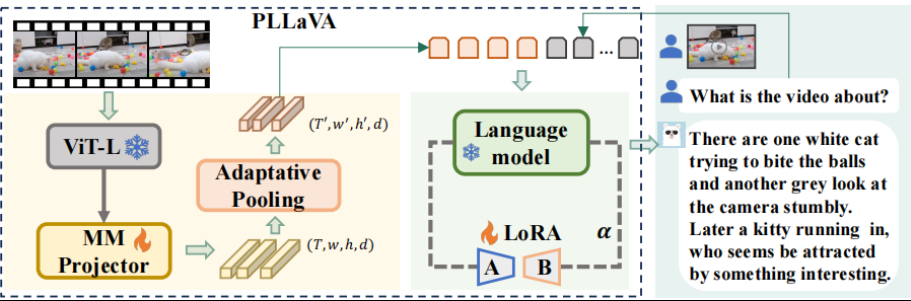

## 사전 준비
1. `.env.example`을 `.env`로 복사하고 `HF_TOKEN`, `HF_DATASET_REPO_ID`(노트북 1에서 업로드한 repo)를 채워넣기
```bash
cp .env.example .env
uv sync
```

In [1]:
import os

os.environ.setdefault("PYTORCH_CUDA_ALLOC_CONF", "expandable_segments:True")

import torch
from dotenv import load_dotenv
from transformers import AutoProcessor, Qwen3VLForConditionalGeneration

import vlm_finetune_utils as vu

load_dotenv()
HF_TOKEN = os.environ["HF_TOKEN"]
HF_DATASET_REPO_ID = os.environ["HF_DATASET_REPO_ID"]

MODEL_ID = "Qwen/Qwen3-VL-2B-Instruct"

# ChartQA_KOR 원본 이미지는 최대 3000px에 달해, Qwen3-VL의 동적 해상도 비전 인코더가
# 매우 많은 이미지 토큰을 만들어 GPU 메모리를 크게 씁니다. min/max_pixels로 상한을 둡니다.
MIN_PIXELS = 256 * 28 * 28
MAX_PIXELS = 512 * 28 * 28

processor = AutoProcessor.from_pretrained(
    MODEL_ID, min_pixels=MIN_PIXELS, max_pixels=MAX_PIXELS
)
model = Qwen3VLForConditionalGeneration.from_pretrained(
    MODEL_ID, torch_dtype=torch.bfloat16, device_map="auto"
)


Loading weights:   0%|          | 0/625 [00:00<?, ?it/s]

## 1. 모듈 이름 확인
어떤 이름의 서브모듈이 Vision Encoder ↔ LLM을 잇는지 먼저 확인합니다.

In [2]:
for name, _ in model.named_modules():
    if "merger" in name:
        print(name)


model.visual.merger
model.visual.merger.norm
model.visual.merger.linear_fc1
model.visual.merger.act_fn
model.visual.merger.linear_fc2
model.visual.deepstack_merger_list
model.visual.deepstack_merger_list.0
model.visual.deepstack_merger_list.0.norm
model.visual.deepstack_merger_list.0.linear_fc1
model.visual.deepstack_merger_list.0.act_fn
model.visual.deepstack_merger_list.0.linear_fc2
model.visual.deepstack_merger_list.1
model.visual.deepstack_merger_list.1.norm
model.visual.deepstack_merger_list.1.linear_fc1
model.visual.deepstack_merger_list.1.act_fn
model.visual.deepstack_merger_list.1.linear_fc2
model.visual.deepstack_merger_list.2
model.visual.deepstack_merger_list.2.norm
model.visual.deepstack_merger_list.2.linear_fc1
model.visual.deepstack_merger_list.2.act_fn
model.visual.deepstack_merger_list.2.linear_fc2


## 2. 전체 동결 후 어댑터(merger)만 해제
"Projector만 Fine-tuning" 전략을 코드로 옮깁니다: Vision Encoder, LLM은 `requires_grad_(False)`로 동결하고, Projector 역할을 하는 `visual.merger`와 `visual.deepstack_merger_list`만 학습 가능하게 둡니다.

In [3]:
for param in model.parameters():
    param.requires_grad_(False)

for name, param in model.named_parameters():
    if "merger" in name:
        param.requires_grad_(True)

model.gradient_checkpointing_enable()
model.config.use_cache = False

trainable, total = vu.count_trainable_params(model)
print(f"학습 파라미터: {trainable:,} / 전체 {total:,} ({trainable / total:.4%})")


학습 파라미터: 100,714,496 / 전체 2,127,532,032 (4.7339%)


## 3. 학습
데이터/collate 방식은 이전 노트북과 동일합니다. 강의 시간 내 실습을 위해 `N_TRAIN`개만 서브샘플링합니다.

In [4]:
from qwen_vl_utils import process_vision_info
from torch.utils.data import DataLoader

N_TRAIN = 200  # 강의 시간 내 실습을 위한 서브셋 크기 (최대 1,600)

vu.download_dataset_from_hub("data", HF_DATASET_REPO_ID, token=HF_TOKEN)
train_records = vu.load_jsonl("data/train/annotations.jsonl")[:N_TRAIN]
train_messages = [vu.to_chat_messages(r, "data/train") for r in train_records]


def collate_fn(batch_messages):
    texts = [
        processor.apply_chat_template(m, tokenize=False, add_generation_prompt=False)
        for m in batch_messages
    ]
    image_inputs, _ = process_vision_info(
        [msg for messages in batch_messages for msg in messages]
    )
    batch = processor(
        text=texts, images=image_inputs, return_tensors="pt", padding=True
    )
    labels = batch["input_ids"].clone()
    # -100은 PyTorch의 CrossEntropyLoss에서 무시(ignore)되는 라벨 값입니다. 
    # 이 코드에서는 패딩(PAD) 토큰을 -100으로 바꾸어 패딩 위치에서는 Loss와 Gradient를 계산하지 않도록 하는 역할을 합니다.
    labels[labels == processor.tokenizer.pad_token_id] = -100
    batch["labels"] = labels
    return batch


loader = DataLoader(train_messages, batch_size=2, shuffle=True, collate_fn=collate_fn)
optimizer = torch.optim.AdamW(
    [p for p in model.parameters() if p.requires_grad], lr=1e-4
)


'data'에 이미 다운로드되어 있어 건너뜁니다.


In [5]:
model.train()
for epoch in range(5):
    total_loss = 0.0
    for batch in loader:
        batch = {k: v.to(model.device) for k, v in batch.items()}
        loss = model(**batch).loss
        loss.backward()
        optimizer.step()
        optimizer.zero_grad()
        total_loss += loss.item()
    print(f"epoch {epoch + 1}/3 - loss {total_loss / len(loader):.4f}")


[transformers] `use_cache=True` is incompatible with gradient checkpointing. Setting `use_cache=False`.


epoch 1/3 - loss 7.9639
epoch 2/3 - loss 6.8361
epoch 3/3 - loss 6.7388
epoch 4/3 - loss 6.7020
epoch 5/3 - loss 6.6844


In [6]:
torch.save(
    {k: v for k, v in model.state_dict().items() if "merger" in k},
    "outputs/vision-adapter.pt",
)
print("저장 완료")


저장 완료


## 전체 방법 비교
이 실습 폴더의 노트북 2, 5에서 각각 출력한 학습 파라미터 수를 아래 표에 채워 비교해보세요. (노트북 4는 가중치를 전혀 학습하지 않으므로 비교 대상에서 제외)

| 방법 | 학습 파라미터 수(대략) | 특징 |
|---|---|---|
| QLoRA (2번 노트북) | 수백만~수천만 | 표현력과 자원 사용의 균형 |
| Vision Adapter (5번 노트북, 이 노트북) | 수백만 (merger 크기에 따라 다름) | 새 이미지 도메인 연결에 특화 |

> 학습 대상(LLM 일부 vs Projector)에 따라 파라미터 수와 효과가 어떻게 달라지는지 숫자로 직접 확인하는 것이 이 노트북의 목적입니다.